In [76]:
from pathlib import Path
import pickle
import matplotlib.gridspec as gridspec
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.pyplot as plt
import cmcrameri.cm as cm

In [77]:

%matplotlib inline
plt.rc('font',family='arial')
plt.rcParams.update({"font.size":6})
font= fm.FontProperties(family='arial')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# cmcrameri.cm.show_cmaps()
mpl._mathtext.SHRINK_FACTOR = 0.666

In [78]:


# data_dir = Path(
#     "/Volumes/University_stuff/Code_Projects/MSGI/plotting/"
#     "Publication_figures/data/IF_development"
# )

# with (data_dir / "IF_development_figure_data.pkl").open("rb") as file:
#     figure_data = pickle.load(file)

# observational_datasets = figure_data["observational_datasets"]
# model_datasets = figure_data["model_datasets"]

# config = figure_data["configuration"]

# timesteps = config["timesteps"]
# x = config["x"]
# x_labels = config["x_labels"]
# ice_phase_thresh = config["ice_phase_thresh"]

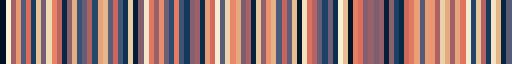

In [79]:
cm.lipariS

In [80]:
colormap=cm.lipariS.colors
color_dd=colormap[2]
color_sev=colormap[3]
color_mod=colormap[0]

In [81]:
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import (
    FixedLocator,
    FixedFormatter,
    MultipleLocator,
    PercentFormatter,
)


# ------------------------------------------------------------------
# Load plotted data
# ------------------------------------------------------------------

data_file = Path(
    "/Volumes/University_stuff/Code_Projects/MSGI/plotting/"
    "Publication_figures/data/IF_development/"
    "IF_development_figure_data.pkl"
)

with data_file.open("rb") as file:
    figure_data = pickle.load(file)

loaded_observations = figure_data["observational_datasets"]
loaded_models = figure_data["model_datasets"]
observational_datasets = figure_data["observational_datasets"]
model_datasets = figure_data["model_datasets"]
configuration = figure_data["configuration"]

timesteps = configuration["timesteps"]
x = np.asarray(configuration["x"])
# x_labels = ['$t_{\\mathrm{peak}}$\n$-30\\,\\mathrm{min}$',
#             '$t_{\\mathrm{peak}}$\n$-15\\,\\mathrm{min}$',
#             '$t_{\\mathrm{peak}}$',
#             '$t_{\\mathrm{peak}}$\n$+15\\,\\mathrm{min}$',
#             '$t_{\\mathrm{peak}}$\n$+30\\,\\mathrm{min}$']
x_labels = [r'-30',
            r'-15',
            r'$\mathrm{{t_{peak}}}$',
            r'+15',
            r'+30']
ice_phase_thresh = configuration["ice_phase_thresh"]


/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_54991/2605559091.py:25: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  figure_data = pickle.load(file)


In [82]:
# ------------------------------------------------------------------
# Plot styling
# ------------------------------------------------------------------

colormap = cm.lipariS.colors

color_dd = colormap[2]
color_sev = colormap[3]
color_mod = colormap[0]

PLOT_STYLE = {
    "figure": {
        "figsize": (5.501, 4.2),
        "constrained_layout": True,
    },

    "datasets": {
        "DARDAR": {
            "color": color_dd,
            "marker": "o",
        },
        "SEVIRI": {
            "color": color_sev,
            "marker": "o",
        },
        "MODIS": {
            "color": color_mod,
            "marker": "^",
        },
        "ICON instant WBF": {
            "color": colormap[4],
            "marker": "D",
        },
        "ICON rate-limited WBF": {
            "color": colormap[0],
            "marker": "D",
        },
        "CESM calibrated": {
            "color": "tab:green",
            "marker": "v",
        },
        "CESM OOTB": {
            "color": "tab:blue",
            "marker": "v",
        },
    },

    "median_line": {
        # "linestyle": ":",
        "linewidth": 2,
        "markersize": 4.5,
        "markeredgewidth": 1,
        "zorder": 3,
    },

    "fraction_line": {
        # "linestyle": "-",
        "linewidth": 2,
        "markersize": 4.5,
        "markeredgewidth": 1,
        "zorder": 3,
    },

    "confidence_band": {
        "alpha": 0.18,
        "linewidth": 0,
        "zorder": 1,
    },

    "axes": {
        "xlim_padding": 0.2,
        "ylim": (0, 1),
        "ytick_interval": 0.2,
        "tick_labelsize": 8,
    },

    "grid": {
        "axis": "y",
        "linestyle": "--",
        "linewidth": 0.7,
        "alpha": 0.35,
    },

    "legend": {
        "frameon": True,
    },
    "Satellite R 150 km": {"color": colormap[5]},
    "Satellite R 15 km": {"color": colormap[3]},
    "ICON 160 km instant WBF": {"color": colormap[4]},
    "ICON 160 km rate-limited WBF": {"color": colormap[0]},
    "CESM 1 deg OOTB": {"color": colormap[5]},
    "CESM 1 deg Calibrated": {"color": colormap[6]},
    
}

In [83]:
# ------------------------------------------------------------------
# Combine loaded data with current styling
# ------------------------------------------------------------------

def apply_dataset_styles(loaded_datasets, style):
    """Replace saved appearance settings while retaining loaded statistics."""

    styled_datasets = {}

    for name, loaded_config in loaded_datasets.items():
        if name not in style["datasets"]:
            raise KeyError(
                f"No styling is defined for dataset {name!r}."
            )

        styled_datasets[name] = {
            "stats": loaded_config["stats"],
            **style["datasets"][name],
        }

    return styled_datasets


observational_datasets = apply_dataset_styles(
    loaded_observations,
    PLOT_STYLE,
)

model_datasets = apply_dataset_styles(
    loaded_models,
    PLOT_STYLE,
)
model_datasets = {"ICON rate-limited WBF": model_datasets['ICON rate-limited WBF'],
                  "ICON instant WBF": model_datasets['ICON instant WBF'] }

In [84]:
def plot_dataset_group(ax_med, ax_frac, datasets, x, style, linestyle):
    for name, dataset_config in datasets.items():
        stats = dataset_config["stats"]
        color = dataset_config["color"]
        marker = dataset_config["marker"]

        ax_med.fill_between(
            x,
            stats["median_ci_low"],
            stats["median_ci_high"],
            color=color,
            **style["confidence_band"],
        )

        ax_med.plot(
            x,
            stats["median"],
            color=color,
            marker=marker,
            label=name,
            linestyle = linestyle,
            **style["fraction_line"],
        )

        ax_frac.fill_between(
            x,
            stats["fraction_ci_low"],
            stats["fraction_ci_high"],
            color=color,
            **style["confidence_band"],
        )

        ax_frac.plot(
            x,
            stats["fraction"],
            color=color,
            marker=marker,
            label=name,
            linestyle = linestyle,
            **style["fraction_line"],
        )

In [85]:
import pandas as pd

# ------------------------------------------------------------------
# Load occurrence-rate results
# ------------------------------------------------------------------

occurrence_file = (
    "/Volumes/University_stuff/Code_Projects/MSGI/"
    "plotting/Publication_figures/data/Occurance_rate/temp_occurrence_rates.csv"
)

temp_occurrence_df = pd.read_csv(
    occurrence_file,
    index_col="Line",
)

# Convert temperature columns from strings to numbers
temp_occurrence_df.columns = temp_occurrence_df.columns.astype(float)

# Convert each row back into a named Series
temp_occurrence_results = {
    name: temp_occurrence_df.loc[name].dropna()
    for name in temp_occurrence_df.iloc[[1,0,3,2]].index
}

Satellite R 15 km
Satellite R 150 km
ICON 160 km rate-limited WBF
ICON 160 km instant WBF


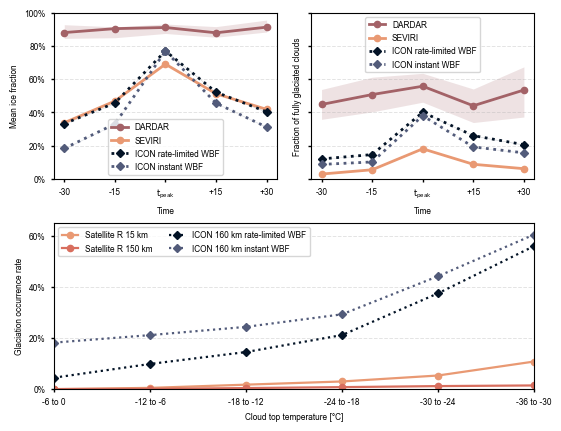

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import (
    FixedLocator,
    FixedFormatter,
    MultipleLocator,
    PercentFormatter,
)



# ------------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------------

fig = plt.figure(
    figsize=(5.501, 4.2),
    constrained_layout=True,
)

gs = gridspec.GridSpec(
    nrows=2,
    ncols=2,
    figure=fig,
    # height_ratios=[1, 1],
    width_ratios=[1, 1],
)

# Observations
ax_med = fig.add_subplot(gs[0, 0])
ax_frac = fig.add_subplot(
    gs[0, 1],
    sharex=ax_med,
)
ax_occ_rate = fig.add_subplot(
    gs[1, :],
)


# ------------------------------------------------------------------
# Plot data
# ------------------------------------------------------------------

plot_dataset_group(
    ax_med=ax_med,
    ax_frac=ax_frac,
    datasets=observational_datasets,
    x=x,
    style=PLOT_STYLE,
    linestyle="-"
)

plot_dataset_group(
    ax_med=ax_med,
    ax_frac=ax_frac,
    datasets=model_datasets,
    x=x,
    style=PLOT_STYLE,
    linestyle=":"
)

# ------------------------------------------------------------------
# Titles
# ------------------------------------------------------------------

# ax_med.set_title(
#     "Median Ice Fraction",
# )

# ax_frac.set_title(
#     "Fully Glaciated Fraction\n"
#     rf"($\mathrm{{IF}} > {ice_phase_thresh:.2f}$)",
# )

# ------------------------------------------------------------------
# Explicit tick formatting
# ------------------------------------------------------------------

all_axes = [
    ax_med,
    ax_frac,
    ax_med,
    ax_frac,
]

for ax in all_axes:
    # Horizontal axis
    ax.set_xlim(-0.2, len(x) - 0.8)
    ax.xaxis.set_major_locator(FixedLocator(x))
    ax.xaxis.set_major_formatter(FixedFormatter(x_labels))

    # Vertical axis
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_major_formatter(
        PercentFormatter(
            xmax=1,
            decimals=0,
        )
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.35,
    )

    ax.tick_params(
        axis="both",
        direction="out",
    )

# Hide x labels on the upper row
# ax_med.tick_params(
#     axis="x",
#     labelbottom=False,
# )

# ax_frac.tick_params(
#     axis="x",
#     labelbottom=False,
# )

# Hide right-column y labels while retaining aligned ticks/gridlines
ax_frac.tick_params(
    axis="y",
    labelleft=False,
)

ax_frac.tick_params(
    axis="y",
    labelleft=False,
)

# ------------------------------------------------------------------
# Axis and row labels
# ------------------------------------------------------------------

# ax_med.set_ylabel(
#     "Observations",
#     fontweight="bold",
# )

# ax_med.set_ylabel(
#     "Models",
#     fontweight="bold",
# )

ax_med.set_xlabel("Time")
ax_frac.set_xlabel("Time")

# ------------------------------------------------------------------
# Legends
# ------------------------------------------------------------------

ax_med.legend(
    loc="lower center",
    frameon=True,
)

ax_frac.legend(
    loc="upper center",
    frameon=True,
)

ax_med.legend(
    loc="lower center",
    frameon=True,
)

ax_frac.legend(
    loc="upper center",
    frameon=True,
)

ax_frac.set_ylabel("Fraction of fully glaciated clouds")
ax_med.set_ylabel("Mean ice fraction")

# ------------------------------------------------------------------
# Glaciation occurrence-rate panel
# ------------------------------------------------------------------

observation_names = [
    "Satellite R 150 km",
    "Satellite R 15 km",
]
for name, values in temp_occurrence_results.items():
    is_observation = name in observation_names
    print(name)
    if name in ["CESM 1 deg Calibrated","CESM 1 deg OOTB"]:
        continue
    ax_occ_rate.plot(
        values.index.astype(float),
        values.to_numpy(),
        label=name,
        color=PLOT_STYLE[name]["color"],
        marker="o" if is_observation else "D",
        linestyle="-" if is_observation else ":",
        linewidth=1.6,
        markersize=4.5,
    )

# Temperature axis
temperatures = np.asarray(
    next(iter(temp_occurrence_results.values())).index,
    dtype=float,
)

ax_occ_rate.set_xlim(temperatures.min(), temperatures.max())
ax_occ_rate.invert_xaxis()

ax_occ_rate.xaxis.set_major_locator(FixedLocator(temperatures))
ax_occ_rate.xaxis.set_major_formatter(
    FixedFormatter([
        f"{temperature:g} to {temperature + 6:g}"
        for temperature in temperatures
    ])
)

ax_occ_rate.set_xlabel("Cloud top temperature [°C]")
ax_occ_rate.set_ylabel("Glaciation occurrence rate")

# Scale the y-axis to the occurrence-rate data
maximum_rate = max(
    np.nanmax(values.to_numpy())
    for values in temp_occurrence_results.values()
)

y_step = 0.2
y_max = np.ceil(maximum_rate / y_step) * y_step

ax_occ_rate.set_ylim(0, 0.65)
ax_occ_rate.yaxis.set_major_locator(MultipleLocator(y_step))
ax_occ_rate.yaxis.set_major_formatter(
    PercentFormatter(xmax=1, decimals=0)
)

ax_occ_rate.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35,
)

ax_occ_rate.tick_params(
    axis="both",
    direction="out",
)

ax_occ_rate.legend(
    loc="upper left",
    frameon=True,
    # fontsize=7,
    ncol=2,
)
# Make ticks lines smaller
for ax in (
    ax_occ_rate,
    ax_med,
    ax_frac):
    ax.tick_params(
        axis="both",
        which="major",
        length=2.5,      # tick-line length
        width=1,     # tick-line thickness
    )

fig.savefig(
            "/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/Multisatellite_IF.pdf",
            dpi=300,
            bbox_inches="tight",
        )